In [27]:
import numpy as np
from hcipy import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from slicing_class import adcFitter2
from scipy import ndimage

In [28]:
def hpf(data,sigma):
    return Field((data.shaped - ndimage.gaussian_filter(data.shaped,sigma)).ravel(),data.grid)

In [29]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

(262144,)

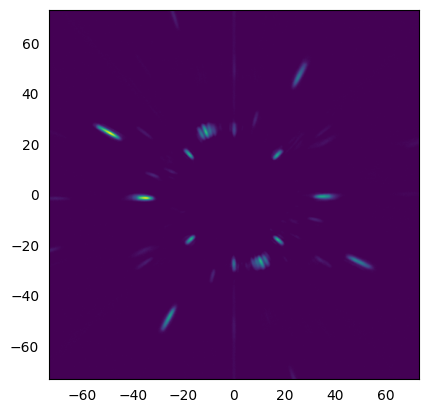

In [30]:
#img = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_unsat.fits')[0]
img = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')[25]
img = hpf(img,20)
img = ADC.crop_image(img,extent=512,mask_diam=20)


#img = img_cube[3]
fig, ax = plt.subplots()
imshow_field(img)
ax.tick_params(left=False,right=False,bottom=False)
img.shape

[54.73780488  0.        ]


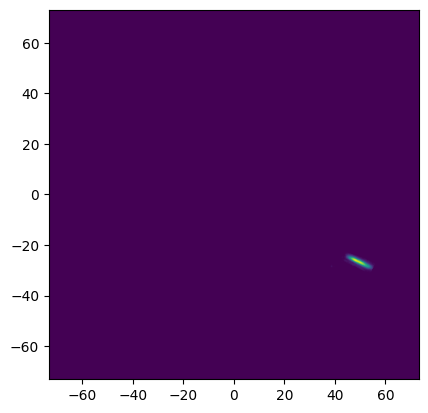

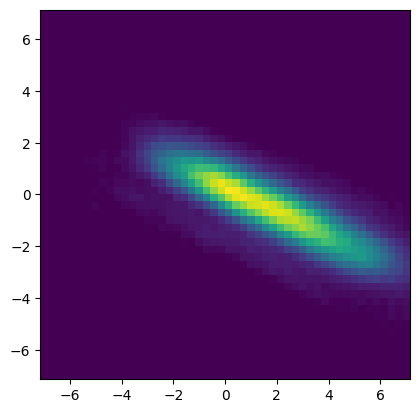

In [31]:
#cut out the speckle window
speckle_number = 1

#locate the general area of the speckle
extent=15
speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
speckle_center = speckle_coords[speckle_number]
print(speckle_center)

#cut out the speckle area
rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
speckle_img = rect * img

#find the center of intensity of the speckle area and window the image around that center
window_size = 50
max_pixel = speckle_img.grid[np.argmax(speckle_img)]
new_img = ADC.window_field(img,[max_pixel[0],max_pixel[1]],window_size,window_size)

#tada!
imshow_field(speckle_img)
plt.figure()
imshow_field(new_img)

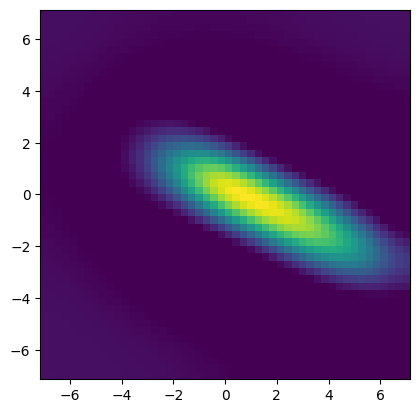

In [32]:
#and now filter it!
hp_sigma = 8
lp_sigma = 3
hp = hpf(new_img,hp_sigma)
lp = hp - hpf(hp,lp_sigma)
lp -= np.median(lp)
lp[lp < 0 ] = 0
new_img = lp
imshow_field(new_img)

In [33]:
#now calculate the image moment
def estimate_angle(data):
    M00 = np.sum(data)
    M10 = np.sum(data * data.grid.x)
    M01 = np.sum(data * data.grid.y)
    
    M20 = np.sum(data * data.grid.x**2)
    M02 = np.sum(data * data.grid.y**2)
    M11 = np.sum(data * data.grid.y * data.grid.x)

    mu10 = M10 / M00
    mu01 = M01 / M00
    mu20 = M20 / M00 - mu10**2
    mu02 = M02 / M00 - mu01**2
    mu11 = M11 / M00 - mu10 * mu01
    angle = (1/2 * np.arctan2(2 * mu11, mu20 - mu02))

    return angle

In [34]:
a = estimate_angle(new_img)
print(np.degrees(a))

-18.223066851464534
